# Figures du rapport — section « Visualisation et statistiques »

Ce notebook régénère **toutes les images** de la partie visualisation de
`reports/report.tex`, avec un **code couleur constant** et en s'appuyant sur
**seaborn** autant que possible.

| # | Fichier | Figure du rapport (`\label`) | Description |
|---|---------|------------------------------|-------------|
| 1 | `repartition_classes.png` | `fig:repartition-classes` | Diagramme en barres des effectifs par classe, un panneau par source (PBC / LMU), échelle log pour rendre visible l'écart d'ordre de grandeur entre classes majoritaires et minoritaires. Ratio max/min annoté (≈ 2,7 pour PBC, ≈ 765 pour LMU). |
| 2 | `mosaique_classes.png` | `fig:mosaique-classes` | Mosaïque d'une image représentative par classe, regroupée par source ; illustre les différences morphologiques inter-classes et l'écart de rendu (cadrage, coloration, fond) entre PBC et LMU. |
| 3a | `histogrammes_rgb.png` | `fig:histogrammes-rgb` | Histogrammes moyens des canaux R, G, B et des niveaux de gris (un panneau par canal), courbes PBC vs LMU superposées — axe y tronqué car les bins 0 et 255 sont saturés. |
| 3b | `histogrammes_rgb_par_type.png` | `fig:histogrammes-rgb` | Les mêmes histogrammes moyens de niveaux de gris, déclinés par type cellulaire, PBC vs LMU. |
| 4 | `luminosite_contraste.png` | `fig:luminosite-contraste` | Boxplots de la luminosité moyenne et du contraste : d'abord par source, puis par classe (couleur = source) — met en évidence l'effet source et l'effet classe. |
| 5 | `nettete.png` | `fig:nettete` | Distribution de l'indicateur de netteté (variance du Laplacien) par source, avec le seuil au 2ᵉ percentile et quelques vignettes d'images signalées comme potentiellement floues. |
| 6 | `format_images.png` | `fig:format-images` | Résolution dominante par source et distribution du poids des fichiers (échelle log) : TIFF LMU ≈ 625 Ko contre JPG PBC ≈ 16 Ko. |
| 7 | `pca_source.png` | `fig:pca-source` | Projection PCA d'un échantillon d'images sur les deux premières composantes, points colorés par source (puis par type) : les images se regroupent d'abord selon leur source. |

**Convention de couleurs** — `PBC` (Barcelone) = bleu `#4C72B0`, `LMU` (Munich) = orange `#DD8452`
(couleurs seaborn `deep`), utilisée dans **toutes** les figures. Types cellulaires (2ᵉ
panneau de la PCA) : palette seaborn `husl`, ordre alphabétique fixe.


In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
%config InlineBackend.figure_format = "retina"

# --- Chemins ---------------------------------------------------------------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures" / "report"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CACHE_CSV = DATA_DIR / "report_sample_image_stats.csv"
CACHE_THUMBS = DATA_DIR / "report_sample_thumbs.npz"

CSV_FULL = DATA_DIR / "blood_cells_data_with_histograms.csv"
assert CSV_FULL.exists(), (
    f"{CSV_FULL} introuvable — lancer d'abord `python -m src.visualization.visualize` "
    "pour générer les CSV d'histogrammes."
)

SEED = 42
N_PER_SOURCE = 2000  # taille cible de l'échantillon par source (netteté + PCA)
rng = np.random.default_rng(SEED)

# --- Style & couleurs -----------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
DEEP = sns.color_palette("deep")
SRC_COLORS = {"PBC": DEEP[0], "LMU": DEEP[1]}          # bleu / orange
SRC_ORDER = ["PBC", "LMU"]

DPI = 200


def save_fig(fig, name: str) -> None:
    """Sauvegarde dans reports/figures/report/ et laisse la figure s'afficher."""
    out = FIG_DIR / name
    fig.savefig(out, dpi=DPI, bbox_inches="tight", facecolor="white")
    print(f"  → {out.relative_to(ROOT)}")


print("Sortie :", FIG_DIR.relative_to(ROOT))

Sortie : reports/figures/report


## Chargement et préparation des métadonnées

In [2]:
# Colonnes d'histogrammes (256 bins par canal), présentes dans le CSV complet.
R_COLS = [f"R{i}" for i in range(256)]
G_COLS = [f"G{i}" for i in range(256)]
B_COLS = [f"B{i}" for i in range(256)]
GRAY_COLS = [f"Gray{i}" for i in range(256)]

# Codes de classe « bruts » tels que présentés dans les tableaux du rapport.
# PBC : préfixe du nom de fichier ; LMU : dossier / abbreviations.txt.
PBC_CODE_NAME = {
    "BA": "Basophile", "BNE": "Neutrophile (band)", "EO": "Éosinophile",
    "ERB": "Érythroblaste", "IG": "Granulocyte immature", "LY": "Lymphocyte",
    "MMY": "Métamyélocyte", "MO": "Monocyte", "MY": "Myélocyte",
    "PLATELET": "Plaquette", "PMY": "Promyélocyte", "SNE": "Neutrophile (segmenté)",
}
LMU_CODE_NAME = {
    "BAS": "Basophile", "EBO": "Érythroblaste", "EOS": "Éosinophile",
    "KSC": "Cellule écrasée", "LYA": "Lymphocyte (atypique)", "LYT": "Lymphocyte (typique)",
    "MMZ": "Métamyélocyte", "MOB": "Monoblaste", "MON": "Monocyte", "MYB": "Myélocyte",
    "MYO": "Myéloblaste", "NGB": "Neutrophile (band)", "NGS": "Neutrophile (segmenté)",
    "PMB": "Promyélocyte (bilobé)", "PMO": "Promyélocyte",
}
# Familles communes aux deux sources (pour les comparaisons par classe).
UNIFIED = {
    "BA": "Basophile", "BAS": "Basophile",
    "BNE": "Neutrophile (band)", "NGB": "Neutrophile (band)",
    "SNE": "Neutrophile (segmenté)", "NGS": "Neutrophile (segmenté)",
    "EO": "Éosinophile", "EOS": "Éosinophile",
    "ERB": "Érythroblaste", "EBO": "Érythroblaste",
    "IG": "Granulocyte immature",
    "MMY": "Métamyélocyte", "MMZ": "Métamyélocyte",
    "MY": "Myélocyte", "MYB": "Myélocyte",
    "MO": "Monocyte", "MON": "Monocyte",
    "LY": "Lymphocyte (typique)", "LYT": "Lymphocyte (typique)",
    "LYA": "Lymphocyte (atypique)",
    "PMY": "Promyélocyte", "PMO": "Promyélocyte", "PMB": "Promyélocyte (bilobé)",
    "MYO": "Myéloblaste", "MOB": "Monoblaste",
    "KSC": "Cellule écrasée", "PLATELET": "Plaquette",
}


def cell_code(row) -> str:
    """Code de classe brut d'une image."""
    if row.dataset == "MUNICH":
        return row.original_type.upper()
    code = Path(row.path).stem.split("_")[0].upper()
    return "SNE" if code == "NEUTROPHIL" else code  # générique -> neutrophile segmenté


df = pd.read_csv(CSV_FULL)
df["source"] = df["dataset"].map({"BARCELONA": "PBC", "MUNICH": "LMU"})
df["code"] = df.apply(cell_code, axis=1)
df["cell"] = df["code"].map(UNIFIED)
df["weight_kb"] = df["size_x"] * df["size_y"]  # placeholder, recalculé sur l'échantillon

print(df.groupby("source")["code"].nunique().rename("n classes"))
print("\nEffectifs totaux :", dict(df.source.value_counts()))
df[["source", "dataset", "path", "code", "cell", "format", "size_x", "size_y"]].head()

/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_86757/3837207054.py:50: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["source"] = df["dataset"].map({"BARCELONA": "PBC", "MUNICH": "LMU"})


source
LMU    15
PBC    12
Name: n classes, dtype: int64

Effectifs totaux : {'LMU': np.int64(18365), 'PBC': np.int64(17092)}


/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_86757/3837207054.py:51: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["code"] = df.apply(cell_code, axis=1)
/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_86757/3837207054.py:52: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["cell"] = df["code"].map(UNIFIED)
/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_86757/3837207054.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many time

,source,dataset,path,code,cell,format,size_x,size_y
0,LMU,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,Cellule écrasée,TIFF,400,400
1,LMU,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,Cellule écrasée,TIFF,400,400
2,LMU,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,Cellule écrasée,TIFF,400,400
3,LMU,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,Cellule écrasée,TIFF,400,400
4,LMU,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,Cellule écrasée,TIFF,400,400


In [3]:
# --- Luminosité & contraste à partir de l'histogramme de niveaux de gris ----
# (données complètes : pas besoin de recharger les images)
_bins = np.arange(256)


def _weighted_mean_std(counts: np.ndarray) -> tuple[float, float]:
    total = counts.sum()
    if total == 0:
        return np.nan, np.nan
    mean = (counts * _bins).sum() / total
    std = np.sqrt((counts * (_bins - mean) ** 2).sum() / total)
    return mean, std


_gray = df[GRAY_COLS].to_numpy(dtype=float)
_totals = _gray.sum(axis=1, keepdims=True)
_totals[_totals == 0] = 1
df["brightness"] = (_gray * _bins).sum(axis=1) / _totals[:, 0]
df["contrast"] = np.sqrt(
    (_gray * (_bins - df["brightness"].to_numpy()[:, None]) ** 2).sum(axis=1) / _totals[:, 0]
)
df[["source", "code", "brightness", "contrast"]].groupby("source").mean(numeric_only=True)

/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_86757/1253621974.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["brightness"] = (_gray * _bins).sum(axis=1) / _totals[:, 0]
/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_86757/1253621974.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["contrast"] = np.sqrt(


,brightness,contrast
source,,
LMU,195.898547,51.879794
PBC,199.700587,40.579194


## Échantillon d'images (netteté + PCA) — avec cache

Le calcul de la netteté (variance du Laplacien) et la PCA demandent de charger les
pixels. On échantillonne ~2000 images par source (stratifié par classe) et on met
les résultats en cache dans `data/` pour accélérer les ré-exécutions.

In [4]:
THUMB = 64  # côté des vignettes conservées pour la PCA


def build_sample() -> tuple[pd.DataFrame, np.ndarray]:
    parts = []
    for src, g in df.groupby("source"):
        n_classes = g["code"].nunique()
        per_class = int(np.ceil(N_PER_SOURCE / n_classes))
        picked = []
        for _, gc in g.groupby("code"):
            picked.append(gc.sample(n=min(len(gc), per_class), random_state=SEED))
        taken = pd.concat(picked)
        # Complément aléatoire pour se rapprocher de N_PER_SOURCE par source
        # (les classes rares de LMU plafonnent vite l'échantillon stratifié).
        rest = g.drop(taken.index)
        short = N_PER_SOURCE - len(taken)
        if short > 0 and len(rest):
            taken = pd.concat([taken, rest.sample(n=min(short, len(rest)), random_state=SEED)])
        parts.append(taken)
    keep = ["source", "dataset", "path", "code", "cell", "format",
            "size_x", "size_y", "brightness", "contrast"]
    sample = pd.concat(parts)[keep].reset_index(drop=True)

    sharp = np.empty(len(sample))
    weight = np.empty(len(sample))
    thumbs = np.empty((len(sample), THUMB, THUMB, 3), dtype=np.uint8)
    for i, path in enumerate(sample["path"]):
        weight[i] = Path(path).stat().st_size / 1024
        bgr = cv2.imread(path, cv2.IMREAD_COLOR)
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        gray256 = cv2.resize(gray, (256, 256), interpolation=cv2.INTER_AREA)
        sharp[i] = cv2.Laplacian(gray256, cv2.CV_64F).var()
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        thumbs[i] = cv2.resize(rgb, (THUMB, THUMB), interpolation=cv2.INTER_AREA)
        if (i + 1) % 500 == 0:
            print(f"  {i + 1}/{len(sample)}")
    sample["sharpness"] = sharp
    sample["weight_kb"] = weight
    return sample, thumbs


if CACHE_CSV.exists() and CACHE_THUMBS.exists():
    sample = pd.read_csv(CACHE_CSV)
    thumbs = np.load(CACHE_THUMBS)["thumbs"]
    print(f"Échantillon rechargé du cache : {len(sample)} images")
else:
    print("Construction de l'échantillon (chargement des images)…")
    sample, thumbs = build_sample()
    sample.to_csv(CACHE_CSV, index=False)
    np.savez_compressed(CACHE_THUMBS, thumbs=thumbs)
    print(f"Cache écrit : {CACHE_CSV.name}, {CACHE_THUMBS.name}")

print(dict(sample.source.value_counts()))
sample[["source", "code", "sharpness", "weight_kb"]].groupby("source").describe().T

Échantillon rechargé du cache : 4000 images
{'LMU': np.int64(2000), 'PBC': np.int64(2000)}


source                   LMU          PBC
sharpness count  2000.000000  2000.000000
          mean     34.849070    84.913858
          std      28.545904    50.078734
          min       8.249179    10.741681
          25%      19.573087    45.887082
          50%      29.094360    78.456591
          75%      42.948521   108.736630
          max     552.804334   356.353087
weight_kb count  2000.000000  2000.000000
          mean    625.151365    16.275972
          std       0.016441     2.423582
          min     625.150391     9.803711
          25%     625.150391    14.677979
          50%     625.150391    16.267578
          75%     625.150391    17.863281
          max     625.428711    26.254883

## Figure 1 — Répartition des classes (`fig:repartition-classes`)

> **Note** — avec la nomenclature brute des tableaux du rapport (12 classes PBC / 15 LMU),
> le ratio max/min est ≈ 20 pour PBC (classe `IG`, générique, quasi vide) et ≈ 771 pour LMU.
> Le « 2,7 » cité dans le corps du rapport correspond à la taxonomie **fusionnée** (8 classes
> PBC), pas aux abréviations brutes.

  → reports/figures/report/repartition_classes.png


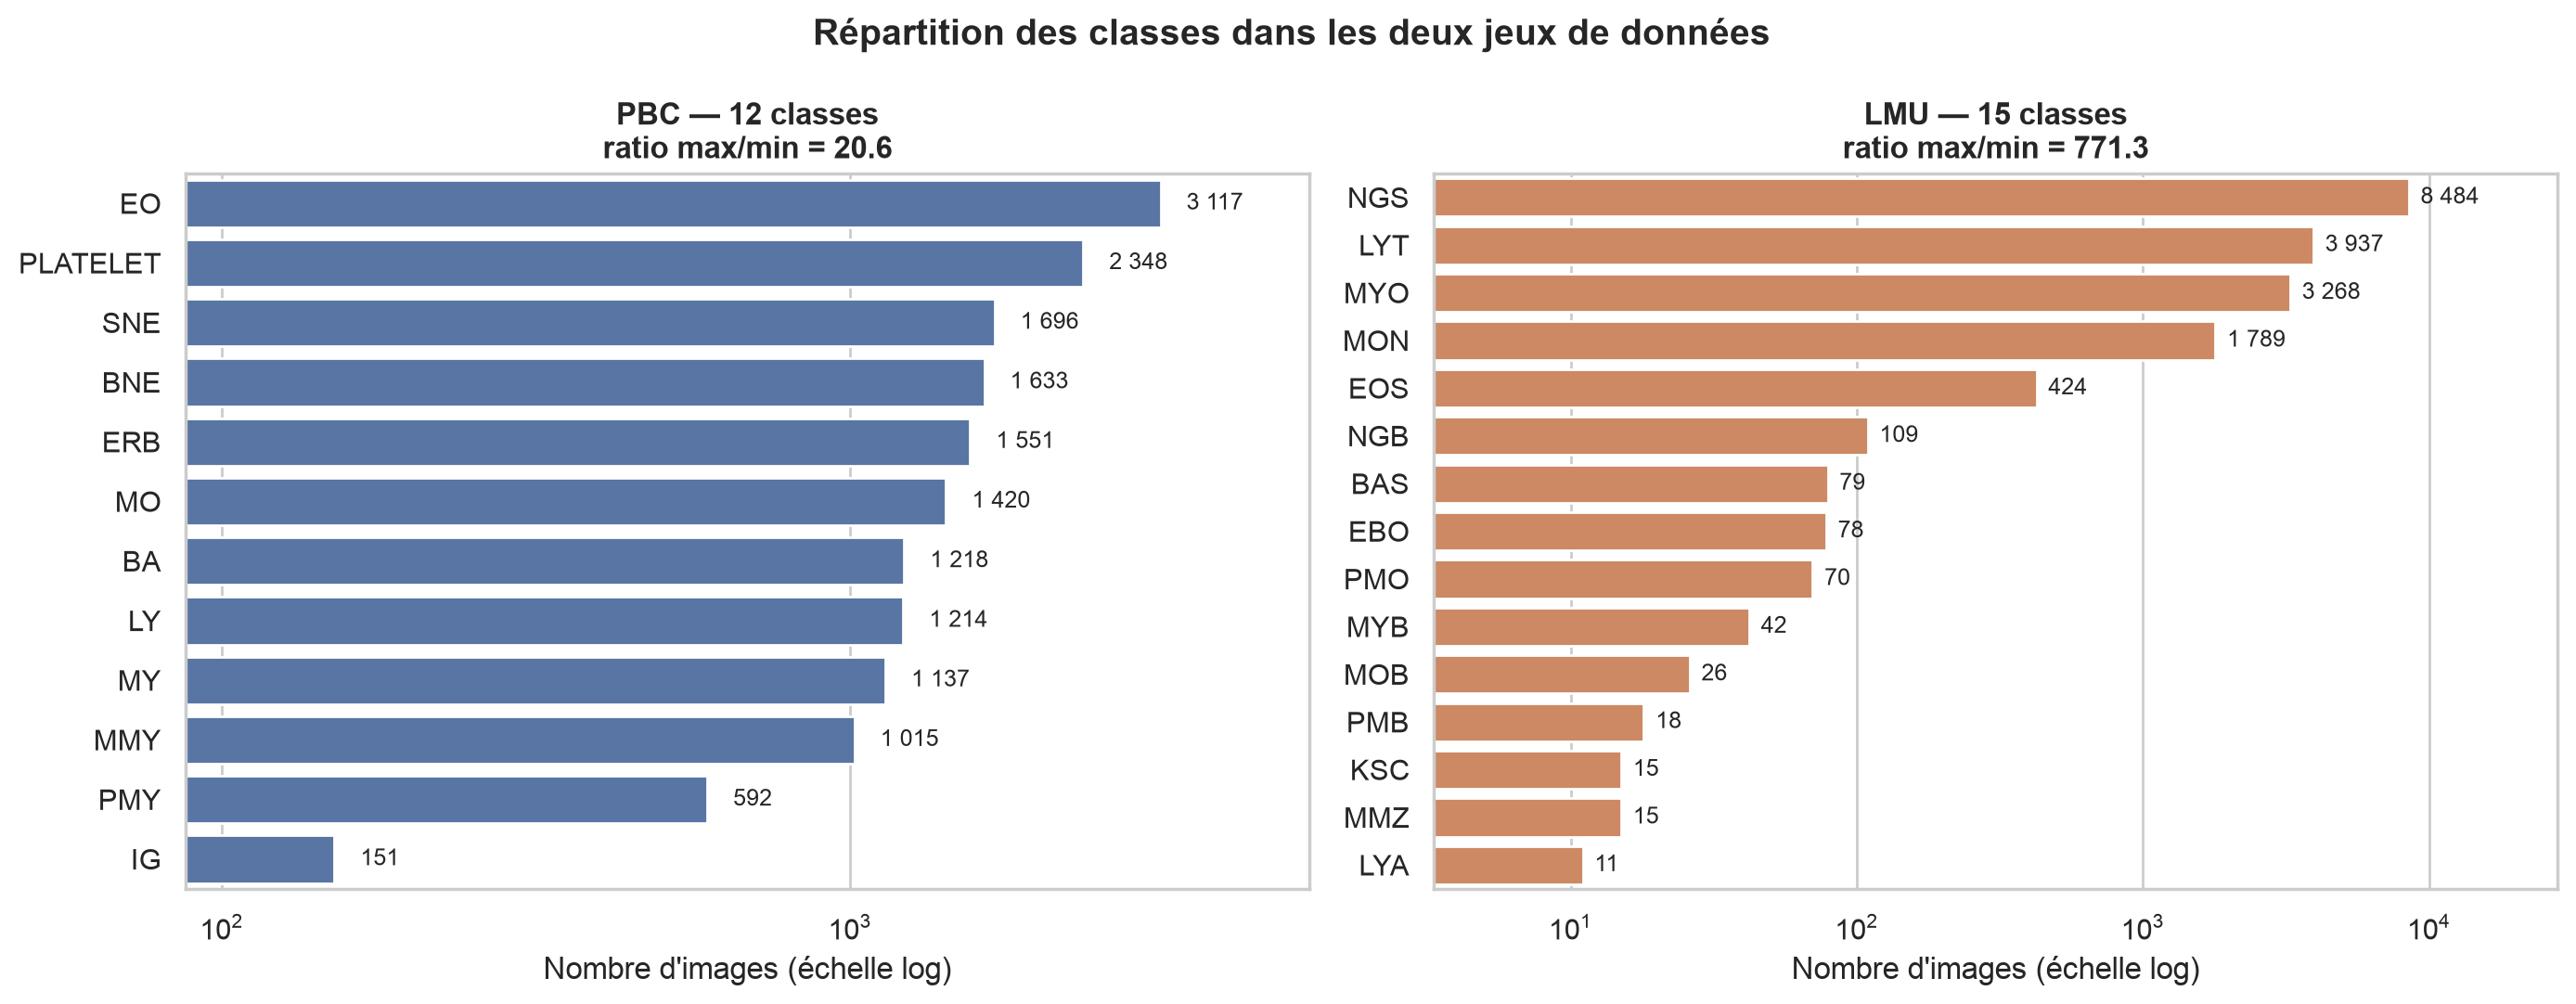

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, src in zip(axes, SRC_ORDER):
    sub = df[df.source == src]
    counts = sub["code"].value_counts()
    ratio = counts.max() / counts.min()
    sns.barplot(x=counts.values, y=counts.index, order=counts.index,
                color=SRC_COLORS[src], ax=ax)
    ax.set_xscale("log")
    ax.set_xlabel("Nombre d'images (échelle log)")
    ax.set_ylabel("")
    ax.set_title(f"{src} — {counts.size} classes\nratio max/min = {ratio:.1f}", fontweight="bold")
    for p, v in zip(ax.patches, counts.values):
        ax.text(v * 1.1, p.get_y() + p.get_height() / 2, f"{v:,}".replace(",", " "),
                va="center", fontsize=9)
    ax.margins(x=0.18)

fig.suptitle("Répartition des classes dans les deux jeux de données", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "repartition_classes.png")
plt.show()

## Figure 2 — Une image par classe et par source (`fig:mosaique-classes`)

  → reports/figures/report/mosaique_classes_pbc.png


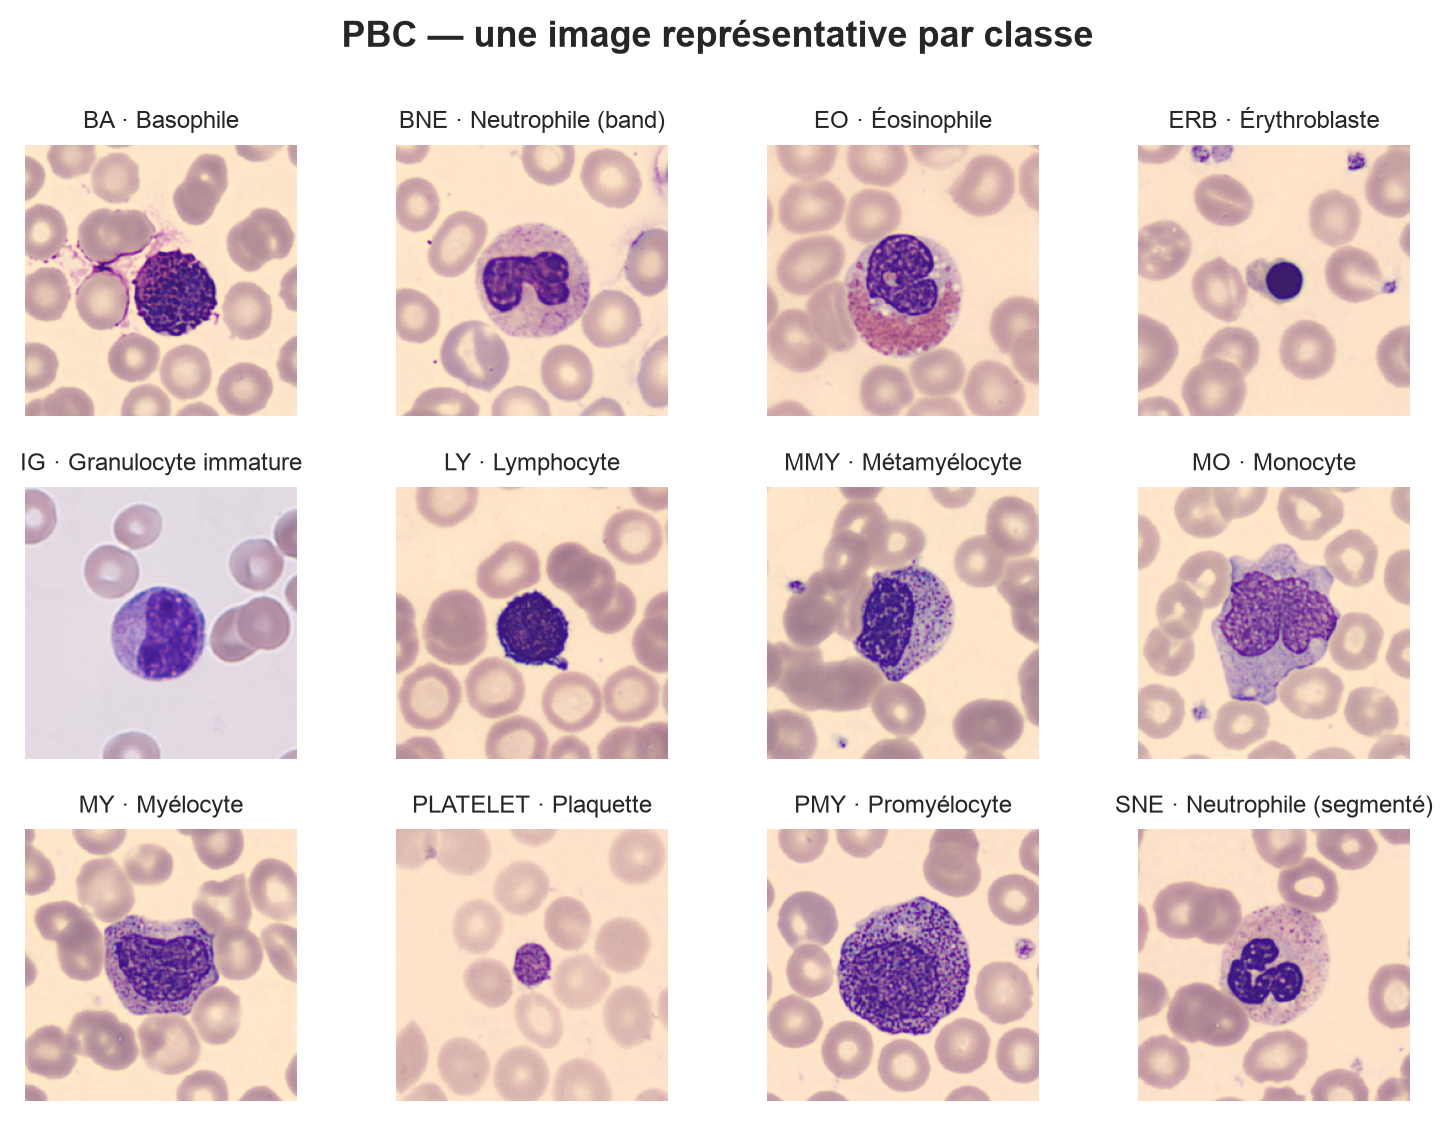

  → reports/figures/report/mosaique_classes_lmu.png


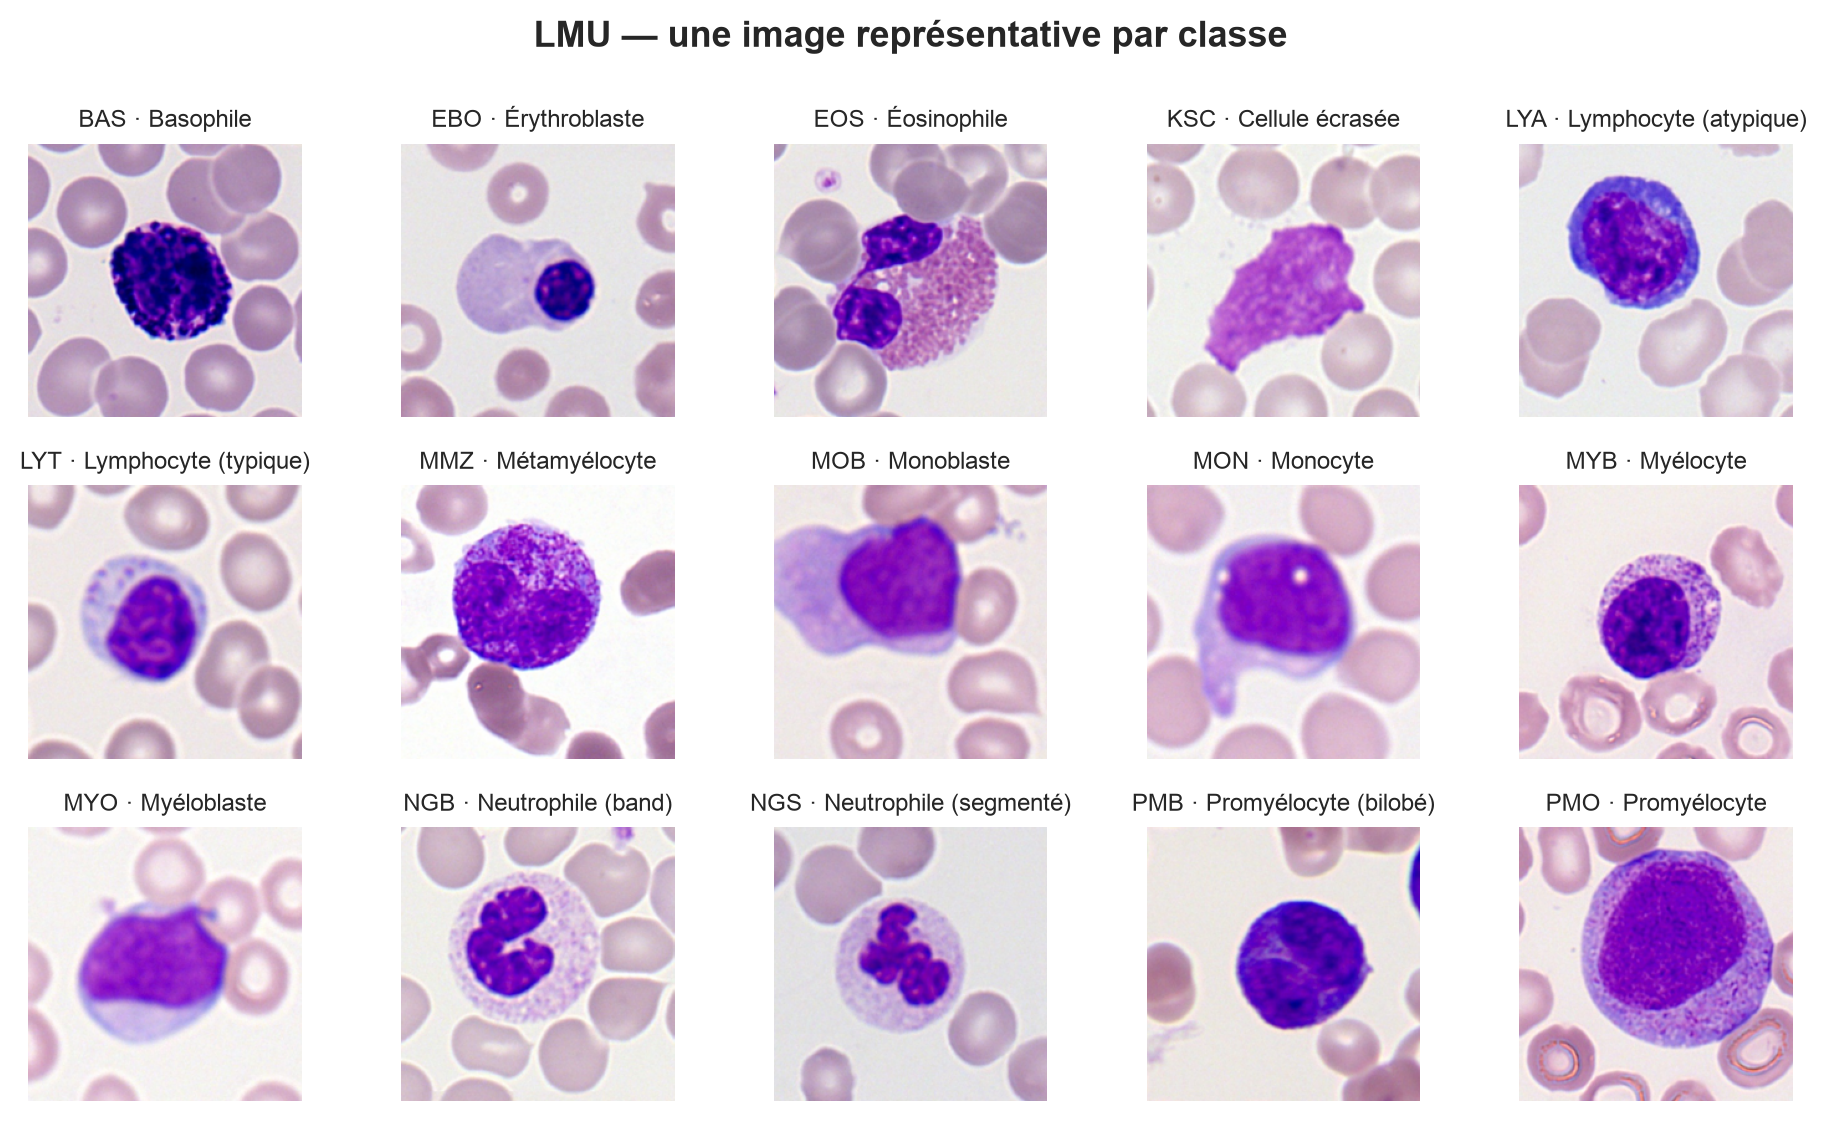

In [6]:
def class_mosaic(src: str, code_name: dict, ncols: int, ax_side: float = 1.9):
    codes = [c for c in code_name if c in set(df[df.source == src]["code"])]
    nrows = int(np.ceil(len(codes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * ax_side, nrows * ax_side))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, c in zip(axes, codes):
        row = df[(df.source == src) & (df.code == c)].sample(1, random_state=SEED).iloc[0]
        with Image.open(row.path) as im:
            ax.imshow(im.convert("RGB").resize((220, 220)))
        ax.set_title(f"{c} · {code_name[c]}", fontsize=8.5)
    fig.suptitle(f"{src} — une image représentative par classe", fontsize=13, fontweight="bold")
    fig.tight_layout()
    return fig


fig = class_mosaic("PBC", PBC_CODE_NAME, ncols=4)
save_fig(fig, "mosaique_classes_pbc.png")
plt.show()

fig = class_mosaic("LMU", LMU_CODE_NAME, ncols=5)
save_fig(fig, "mosaique_classes_lmu.png")
plt.show()

  → reports/figures/report/mosaique_classes.png


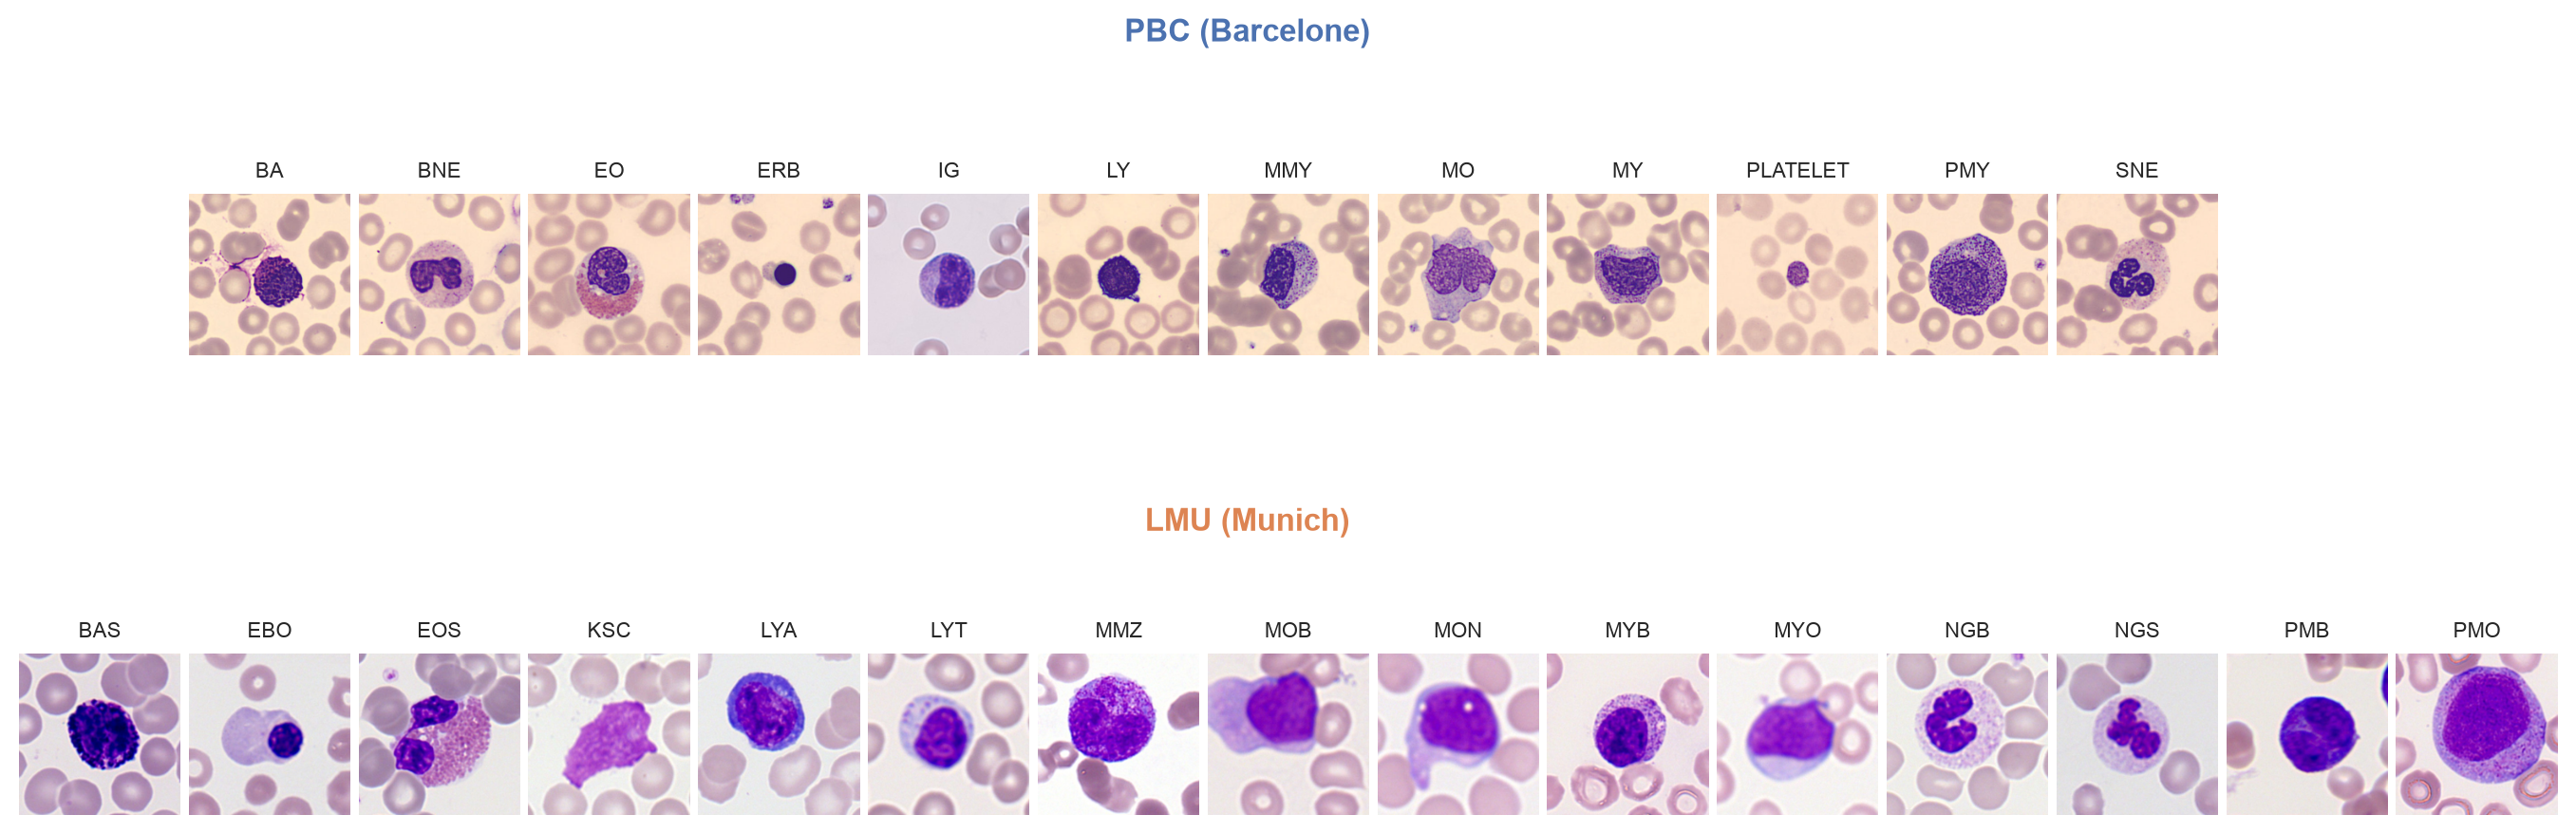

In [7]:
# Version combinée en une seule image (celle référencée par le rapport).
def _row_of_thumbs(fig, gs_row, src, codes, code_name, ncols):
    offset = (ncols - len(codes)) // 2  # centre la rangée la plus courte
    for k in range(ncols):
        ax = fig.add_subplot(gs_row[k])
        ax.axis("off")
        j = k - offset
        if 0 <= j < len(codes):
            c = codes[j]
            row = df[(df.source == src) & (df.code == c)].sample(1, random_state=SEED).iloc[0]
            with Image.open(row.path) as im:
                ax.imshow(im.convert("RGB").resize((200, 200)))
            ax.set_title(f"{c}", fontsize=8)


pbc_codes = [c for c in PBC_CODE_NAME if c in set(df[df.source == "PBC"]["code"])]
lmu_codes = [c for c in LMU_CODE_NAME if c in set(df[df.source == "LMU"]["code"])]
ncols = 15
fig = plt.figure(figsize=(ncols * 1.15, 5.6))
outer = fig.add_gridspec(2, 1, hspace=0.28)
top = outer[0].subgridspec(1, ncols, wspace=0.05)
bot = outer[1].subgridspec(1, ncols, wspace=0.05)
_row_of_thumbs(fig, top, "PBC", pbc_codes, PBC_CODE_NAME, ncols)
_row_of_thumbs(fig, bot, "LMU", lmu_codes, LMU_CODE_NAME, ncols)
fig.text(0.5, 0.93, "PBC (Barcelone)", ha="center", fontsize=12, fontweight="bold",
         color=SRC_COLORS["PBC"])
fig.text(0.5, 0.47, "LMU (Munich)", ha="center", fontsize=12, fontweight="bold",
         color=SRC_COLORS["LMU"])
save_fig(fig, "mosaique_classes.png")
plt.show()

## Figure 3 — Distributions colorimétriques (`fig:histogrammes-rgb`)

  → reports/figures/report/histogrammes_rgb.png


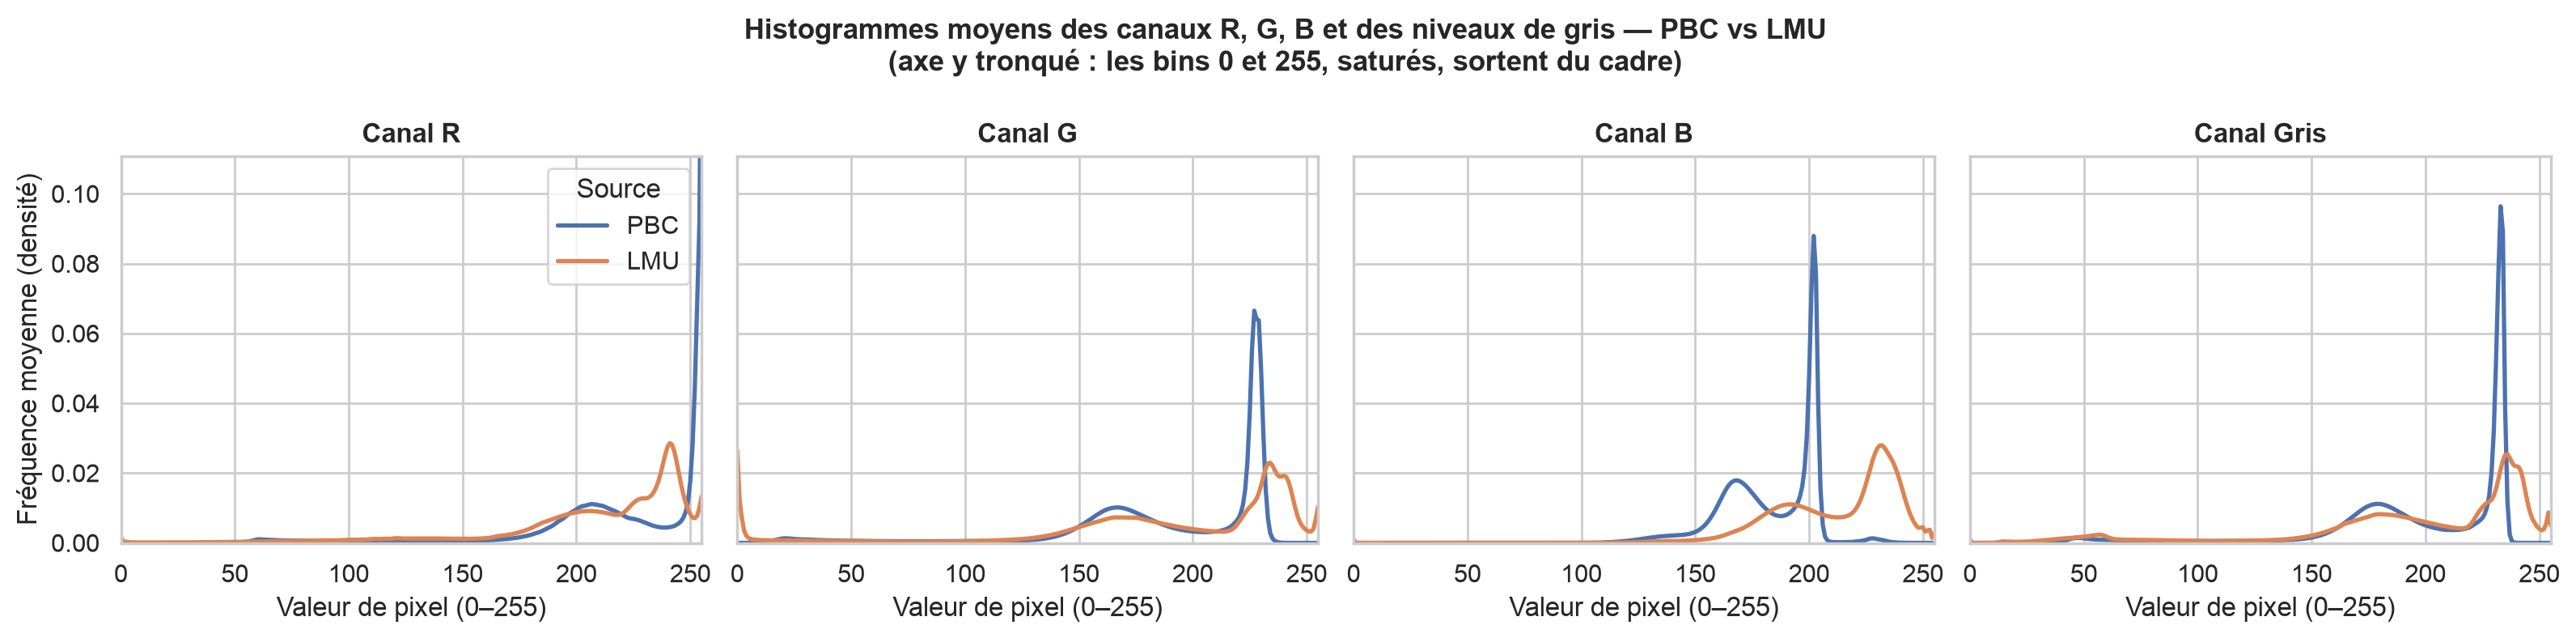

In [8]:
def mean_density(frame: pd.DataFrame, cols: list[str]) -> np.ndarray:
    """Histogramme moyen normalisé (densité) sur un ensemble d'images."""
    arr = frame[cols].to_numpy(dtype=float)
    arr = arr / arr.sum(axis=1, keepdims=True).clip(min=1)
    return arr.mean(axis=0)


# Un panneau par canal, PBC vs LMU superposés (code couleur = source).
channels = [("R", R_COLS), ("G", G_COLS), ("B", B_COLS), ("Gris", GRAY_COLS)]
dens = {src: {ch: mean_density(df[df.source == src], cols) for ch, cols in channels}
        for src in SRC_ORDER}
ymax = max(v[10:250].max() for s in dens.values() for v in s.values())  # ignore bins 0 / 255

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, (ch, _) in zip(axes, channels):
    for src in SRC_ORDER:
        ax.plot(dens[src][ch], color=SRC_COLORS[src], lw=1.9, label=src)
    ax.set_title(f"Canal {ch}", fontweight="bold")
    ax.set_xlabel("Valeur de pixel (0–255)")
    ax.set_xlim(0, 255)
    ax.set_ylim(0, ymax * 1.15)
axes[0].set_ylabel("Fréquence moyenne (densité)")
axes[0].legend(title="Source", frameon=True)
fig.suptitle("Histogrammes moyens des canaux R, G, B et des niveaux de gris — PBC vs LMU\n"
             "(axe y tronqué : les bins 0 et 255, saturés, sortent du cadre)",
             fontsize=12.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "histogrammes_rgb.png")
plt.show()

  → reports/figures/report/histogrammes_rgb_par_type.png


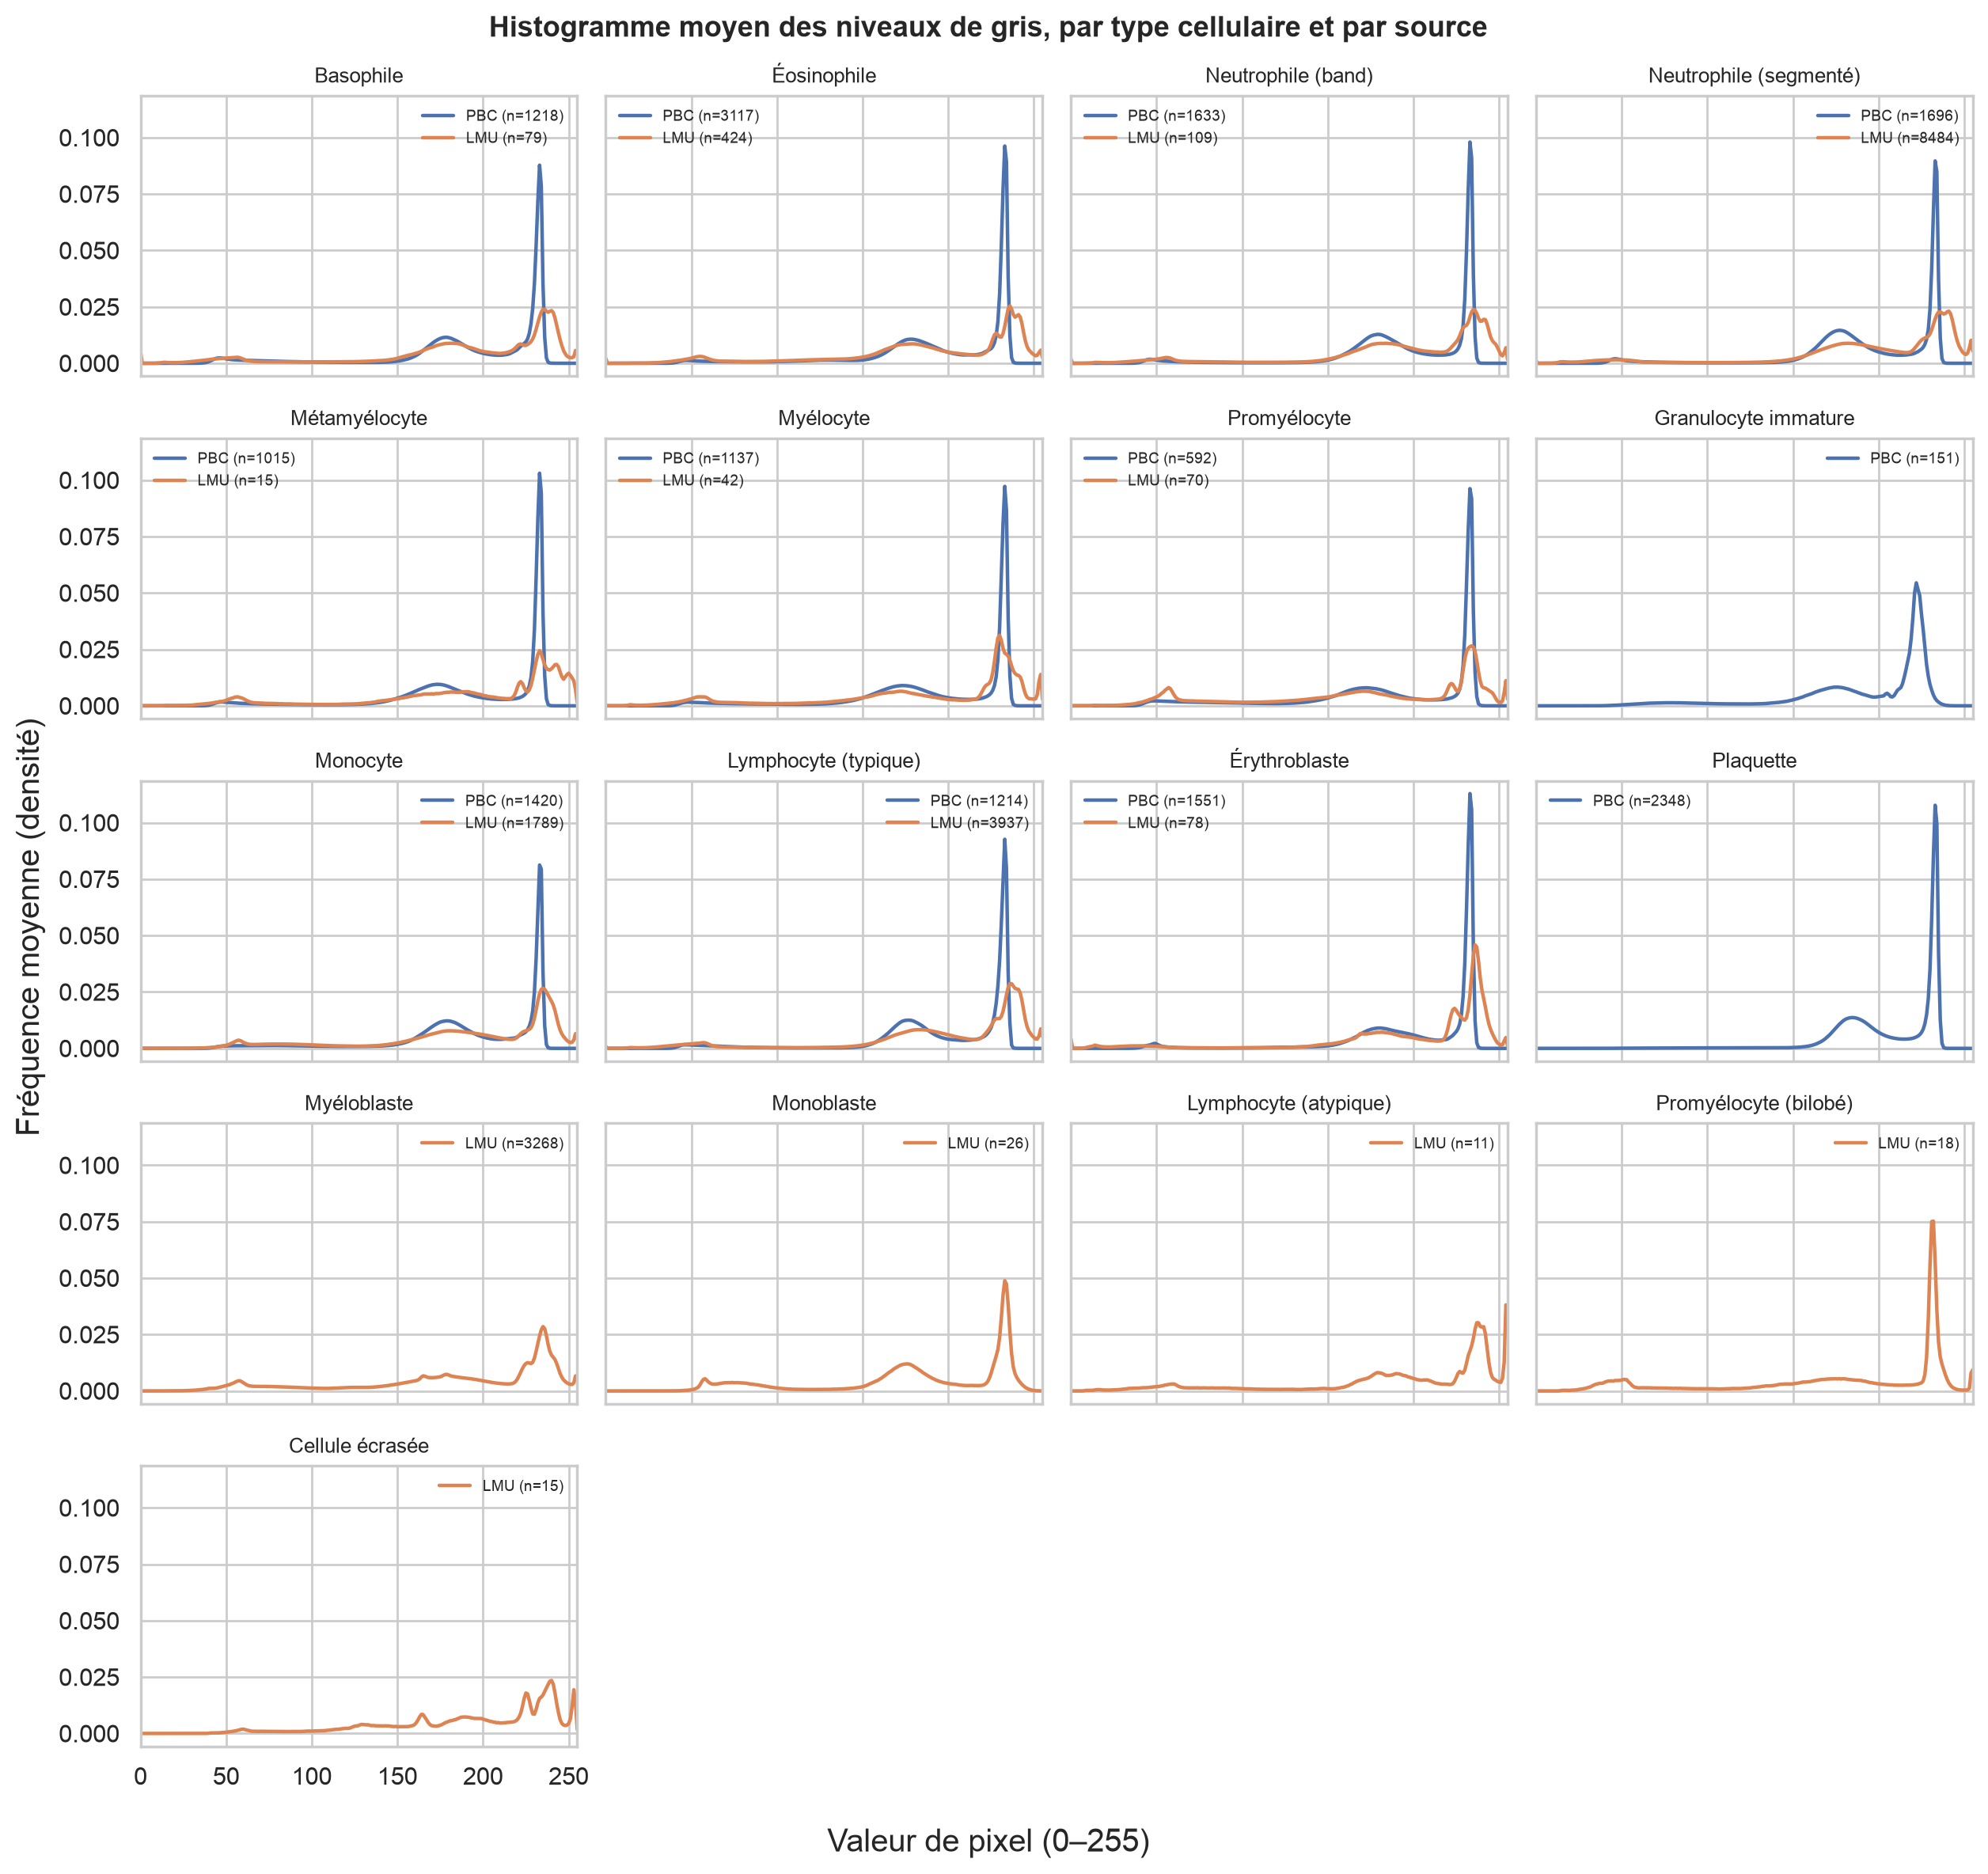

In [9]:
# Décliné par type cellulaire : niveaux de gris moyens, PBC vs LMU.
cells_order = [
    "Basophile", "Éosinophile", "Neutrophile (band)", "Neutrophile (segmenté)",
    "Métamyélocyte", "Myélocyte", "Promyélocyte", "Granulocyte immature",
    "Monocyte", "Lymphocyte (typique)", "Érythroblaste", "Plaquette",
    "Myéloblaste", "Monoblaste", "Lymphocyte (atypique)", "Promyélocyte (bilobé)",
    "Cellule écrasée",
]
cells_present = [c for c in cells_order if c in df["cell"].dropna().unique()]
ncols = 4
nrows = int(np.ceil(len(cells_present) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.2, nrows * 2.4),
                         sharex=True, sharey=True)
axes = axes.ravel()
for ax in axes:
    ax.axis("off")
for ax, cell in zip(axes, cells_present):
    ax.axis("on")
    for src in SRC_ORDER:
        sub = df[(df.cell == cell) & (df.source == src)]
        if len(sub):
            ax.plot(mean_density(sub, GRAY_COLS), color=SRC_COLORS[src], lw=1.6,
                    label=f"{src} (n={len(sub)})")
    ax.set_title(cell, fontsize=9.5)
    ax.legend(fontsize=7, frameon=False)
    ax.set_xlim(0, 255)
fig.suptitle("Histogramme moyen des niveaux de gris, par type cellulaire et par source",
             fontsize=13, fontweight="bold")
fig.supxlabel("Valeur de pixel (0–255)")
fig.supylabel("Fréquence moyenne (densité)")
fig.tight_layout()
save_fig(fig, "histogrammes_rgb_par_type.png")
plt.show()

## Figure 4 — Luminosité et contraste (`fig:luminosite-contraste`)

  → reports/figures/report/luminosite_contraste.png


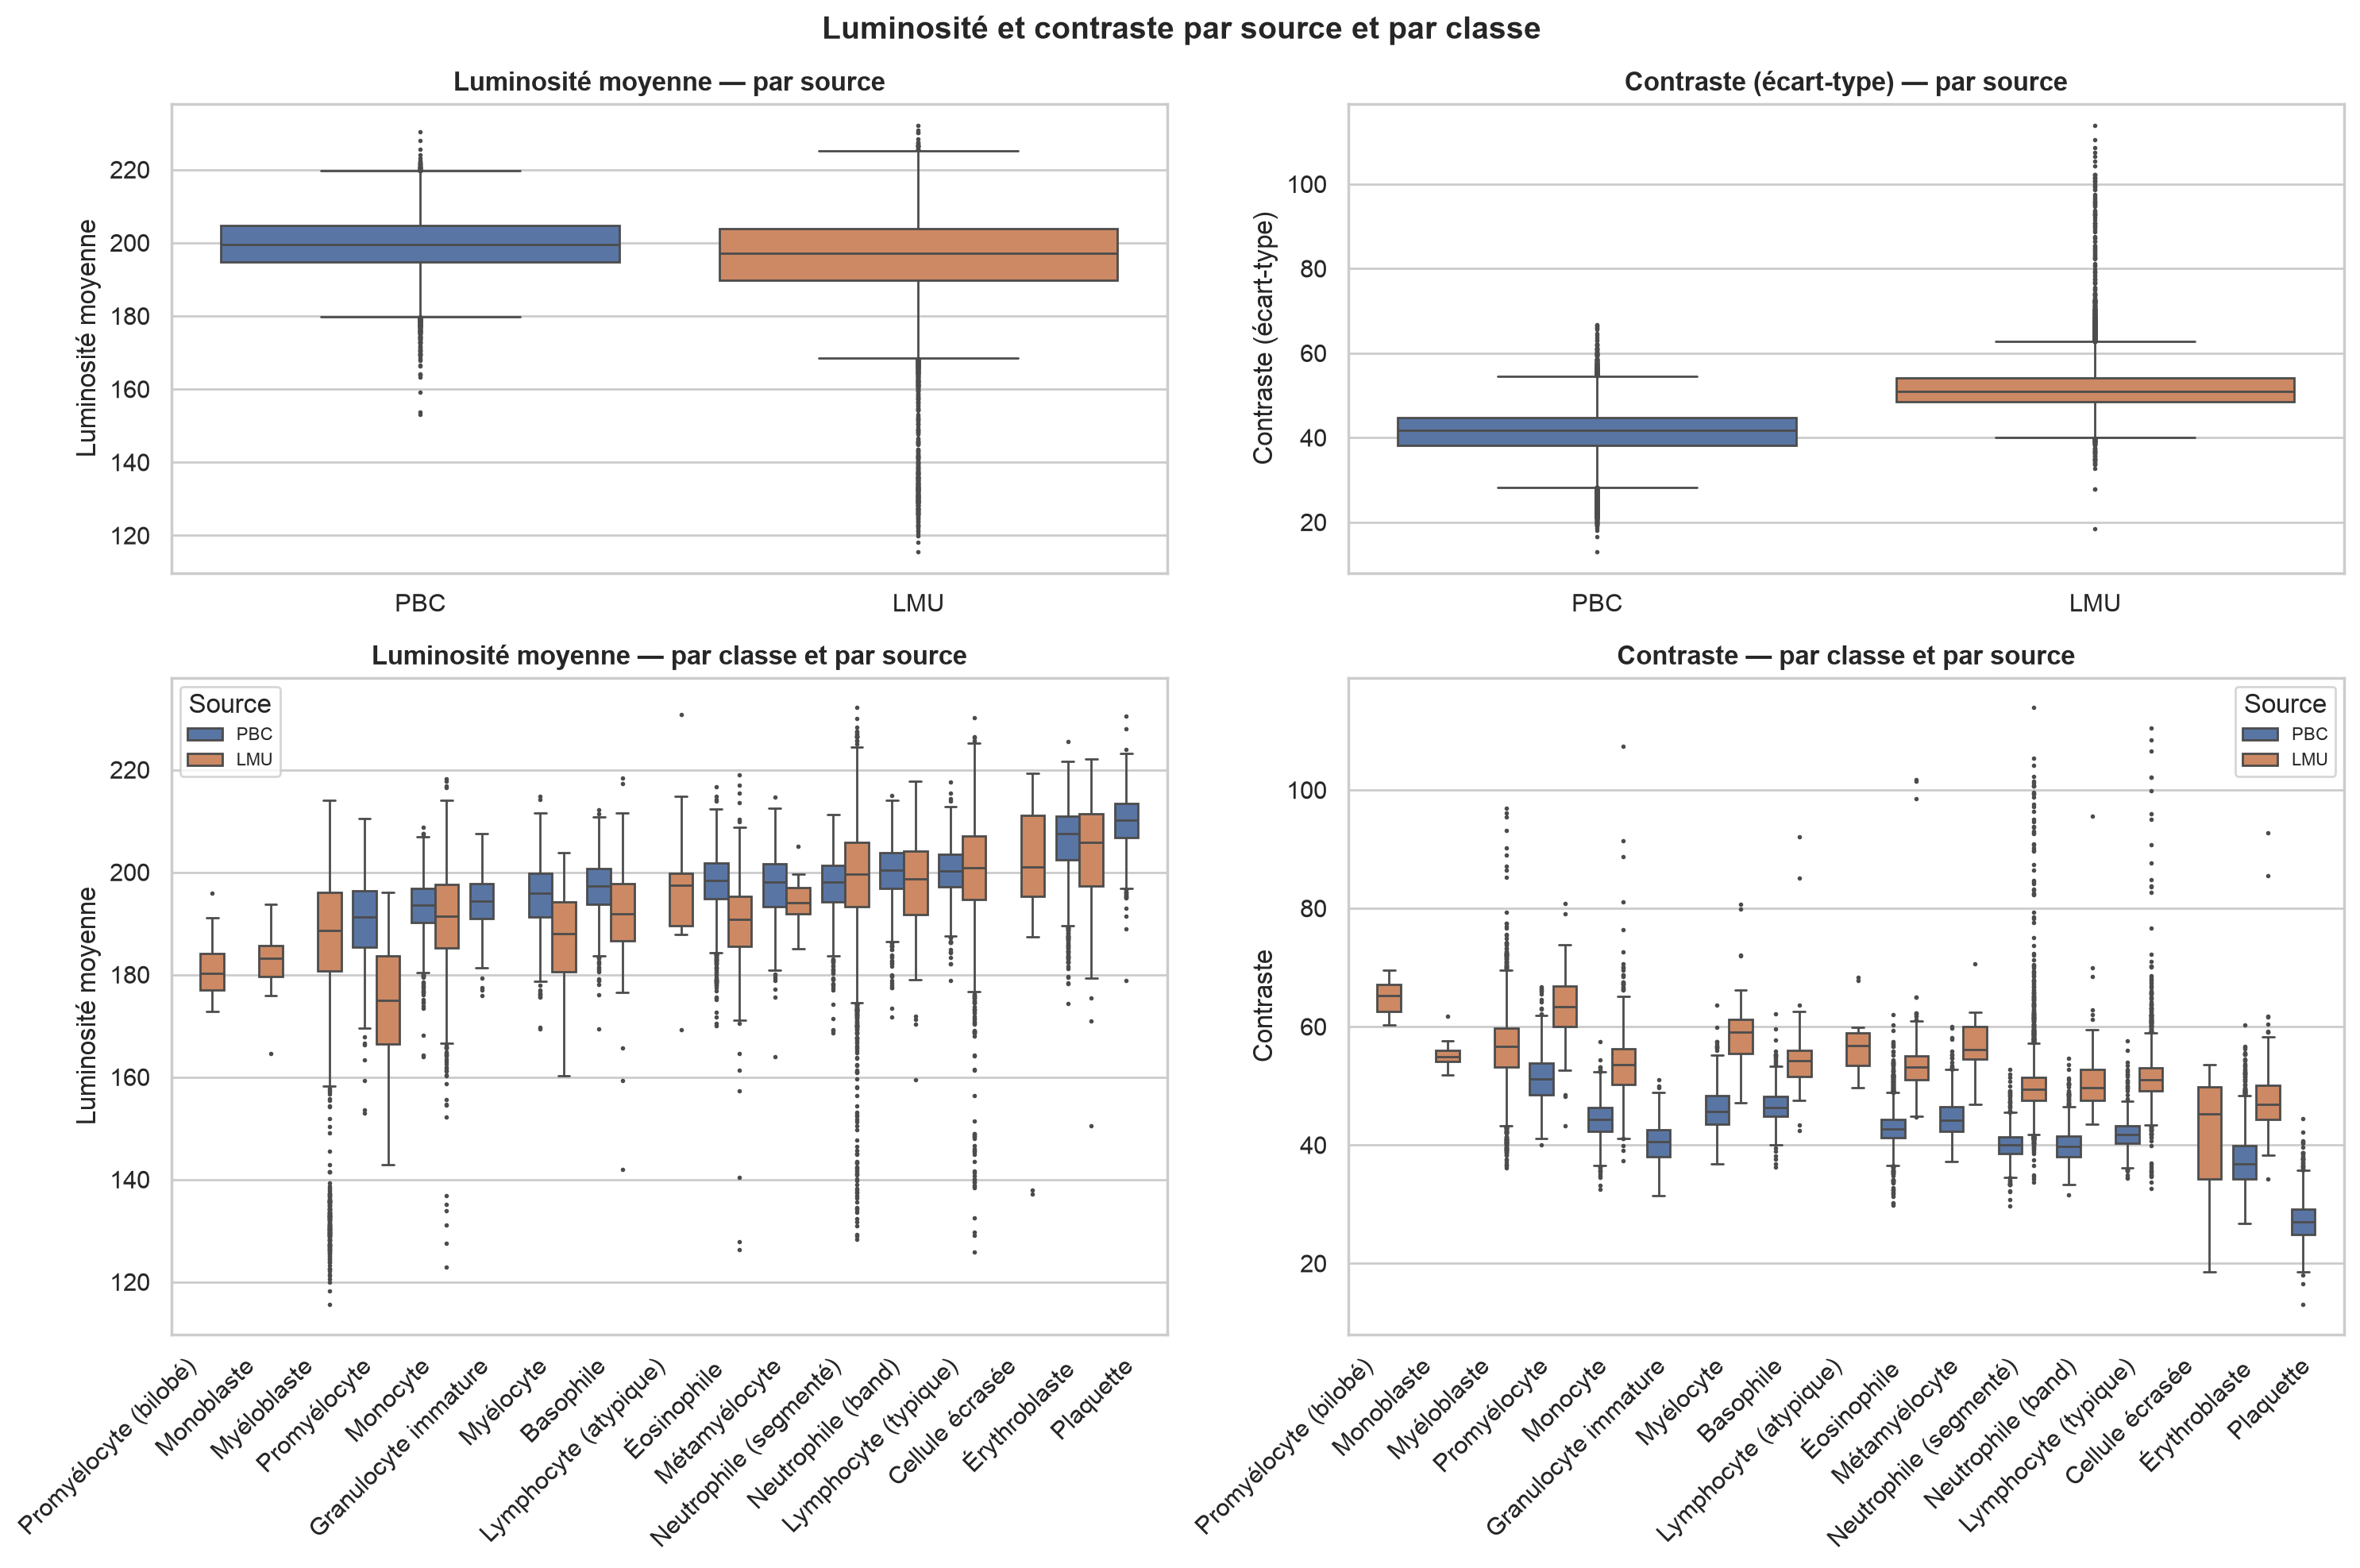

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10),
                         gridspec_kw={"height_ratios": [1, 1.4]})

for ax, metric, label in [(axes[0, 0], "brightness", "Luminosité moyenne"),
                          (axes[0, 1], "contrast", "Contraste (écart-type)")]:
    sns.boxplot(data=df, x="source", y=metric, order=SRC_ORDER, hue="source",
                palette=SRC_COLORS, legend=False, ax=ax, fliersize=1)
    ax.set_title(f"{label} — par source", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(label)

cell_order = (
    df.groupby("cell")["brightness"].median().sort_values().index.tolist()
)
for ax, metric, label in [(axes[1, 0], "brightness", "Luminosité moyenne"),
                          (axes[1, 1], "contrast", "Contraste")]:
    sns.boxplot(data=df.dropna(subset=["cell"]), x="cell", y=metric, order=cell_order,
                hue="source", hue_order=SRC_ORDER, palette=SRC_COLORS, ax=ax, fliersize=1)
    ax.set_title(f"{label} — par classe et par source", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.tick_params(axis="x", rotation=45)
    for lab in ax.get_xticklabels():
        lab.set_ha("right")
    ax.legend(title="Source", fontsize=8)

fig.suptitle("Luminosité et contraste par source et par classe", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "luminosite_contraste.png")
plt.show()

## Figure 5 — Netteté et images potentiellement floues (`fig:nettete`)

  → reports/figures/report/nettete.png


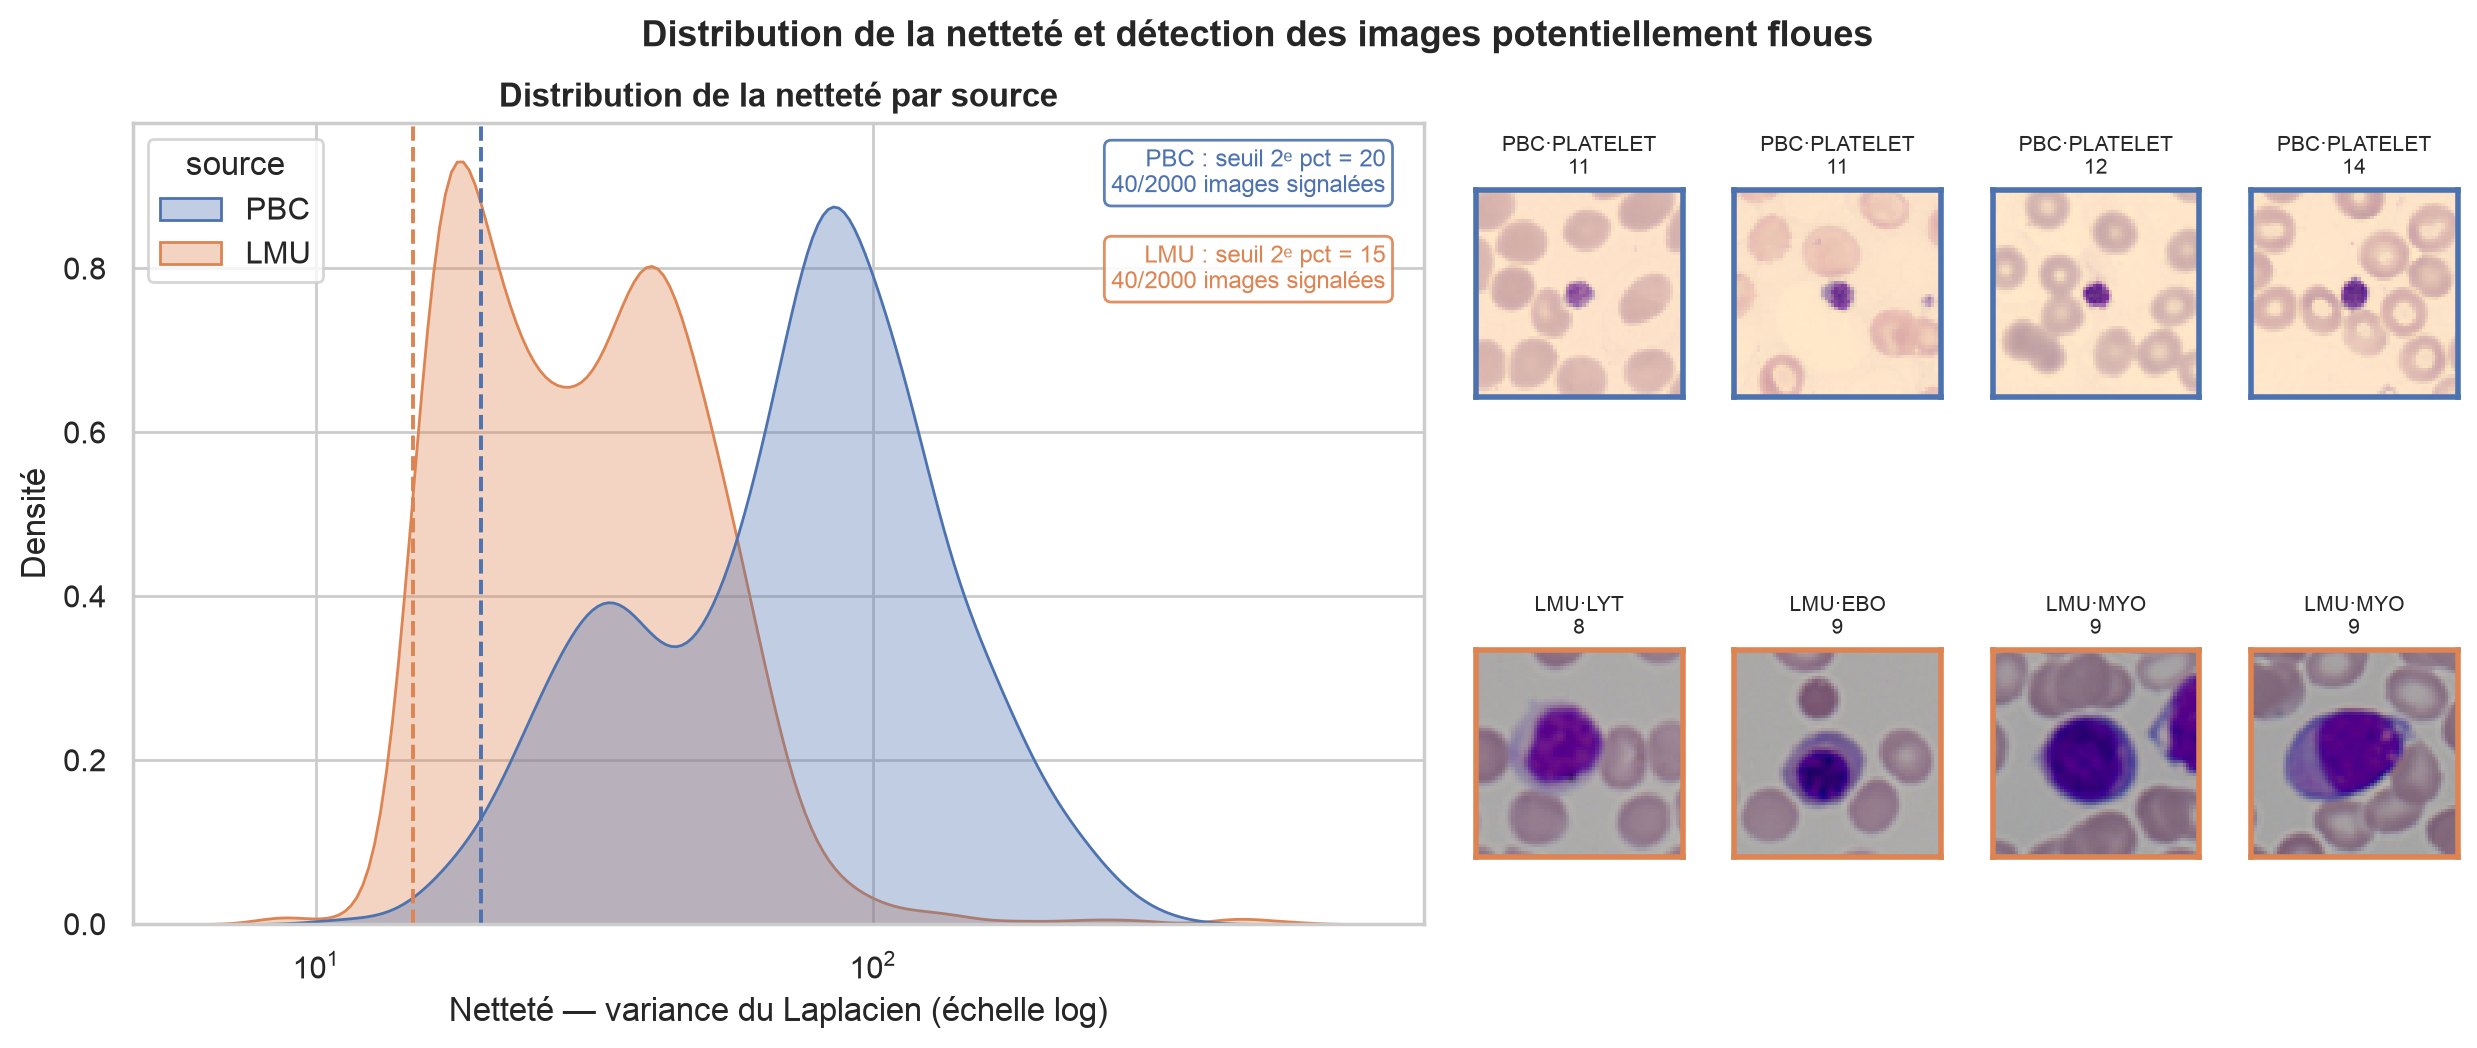

In [11]:
fig = plt.figure(figsize=(15, 5.2))
gs = fig.add_gridspec(2, 6, width_ratios=[3, 3, 1, 1, 1, 1], hspace=0.35, wspace=0.15)
ax_kde = fig.add_subplot(gs[:, :2])

sns.kdeplot(data=sample, x="sharpness", hue="source", hue_order=SRC_ORDER,
            palette=SRC_COLORS, fill=True, alpha=0.35, log_scale=True, ax=ax_kde)
ax_kde.set_xlabel("Netteté — variance du Laplacien (échelle log)")
ax_kde.set_ylabel("Densité")
ax_kde.set_title("Distribution de la netteté par source", fontweight="bold")

flagged = {}
for i, src in enumerate(SRC_ORDER):
    s = sample[sample.source == src]
    thr = s["sharpness"].quantile(0.02)
    flagged[src] = s[s["sharpness"] <= thr]
    ax_kde.axvline(thr, color=SRC_COLORS[src], ls="--", lw=1.4)
    ax_kde.text(0.97, 0.97 - 0.12 * i,
                f"{src} : seuil 2ᵉ pct = {thr:.0f}\n"
                f"{len(flagged[src])}/{len(s)} images signalées",
                transform=ax_kde.transAxes, ha="right", va="top",
                color=SRC_COLORS[src], fontsize=8.5,
                bbox=dict(boxstyle="round", fc="white", ec=SRC_COLORS[src], alpha=0.9))

# Vignettes des images les plus floues (2 par source).
slots = [gs[0, 2], gs[0, 3], gs[0, 4], gs[0, 5], gs[1, 2], gs[1, 3], gs[1, 4], gs[1, 5]]
picks = []
for src in SRC_ORDER:
    picks += list(flagged[src].sort_values("sharpness").head(4).index)
for slot, idx in zip(slots, picks):
    ax = fig.add_subplot(slot)
    ax.imshow(thumbs[idx])
    ax.set_xticks([])
    ax.set_yticks([])
    r = sample.loc[idx]
    ax.set_title(f"{r.source}·{r.code}\n{r.sharpness:.0f}", fontsize=7.5)
    for sp in ax.spines.values():
        sp.set_color(SRC_COLORS[r.source])
        sp.set_linewidth(2)

fig.suptitle("Distribution de la netteté et détection des images potentiellement floues",
             fontsize=13, fontweight="bold")
save_fig(fig, "nettete.png")
plt.show()

## Figure 6 — Format, résolution et poids des images (`fig:format-images`)

/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_86757/1303708965.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  res = (df.assign(resolution=df["size_x"].astype(str) + "×" + df["size_y"].astype(str))


  → reports/figures/report/format_images.png


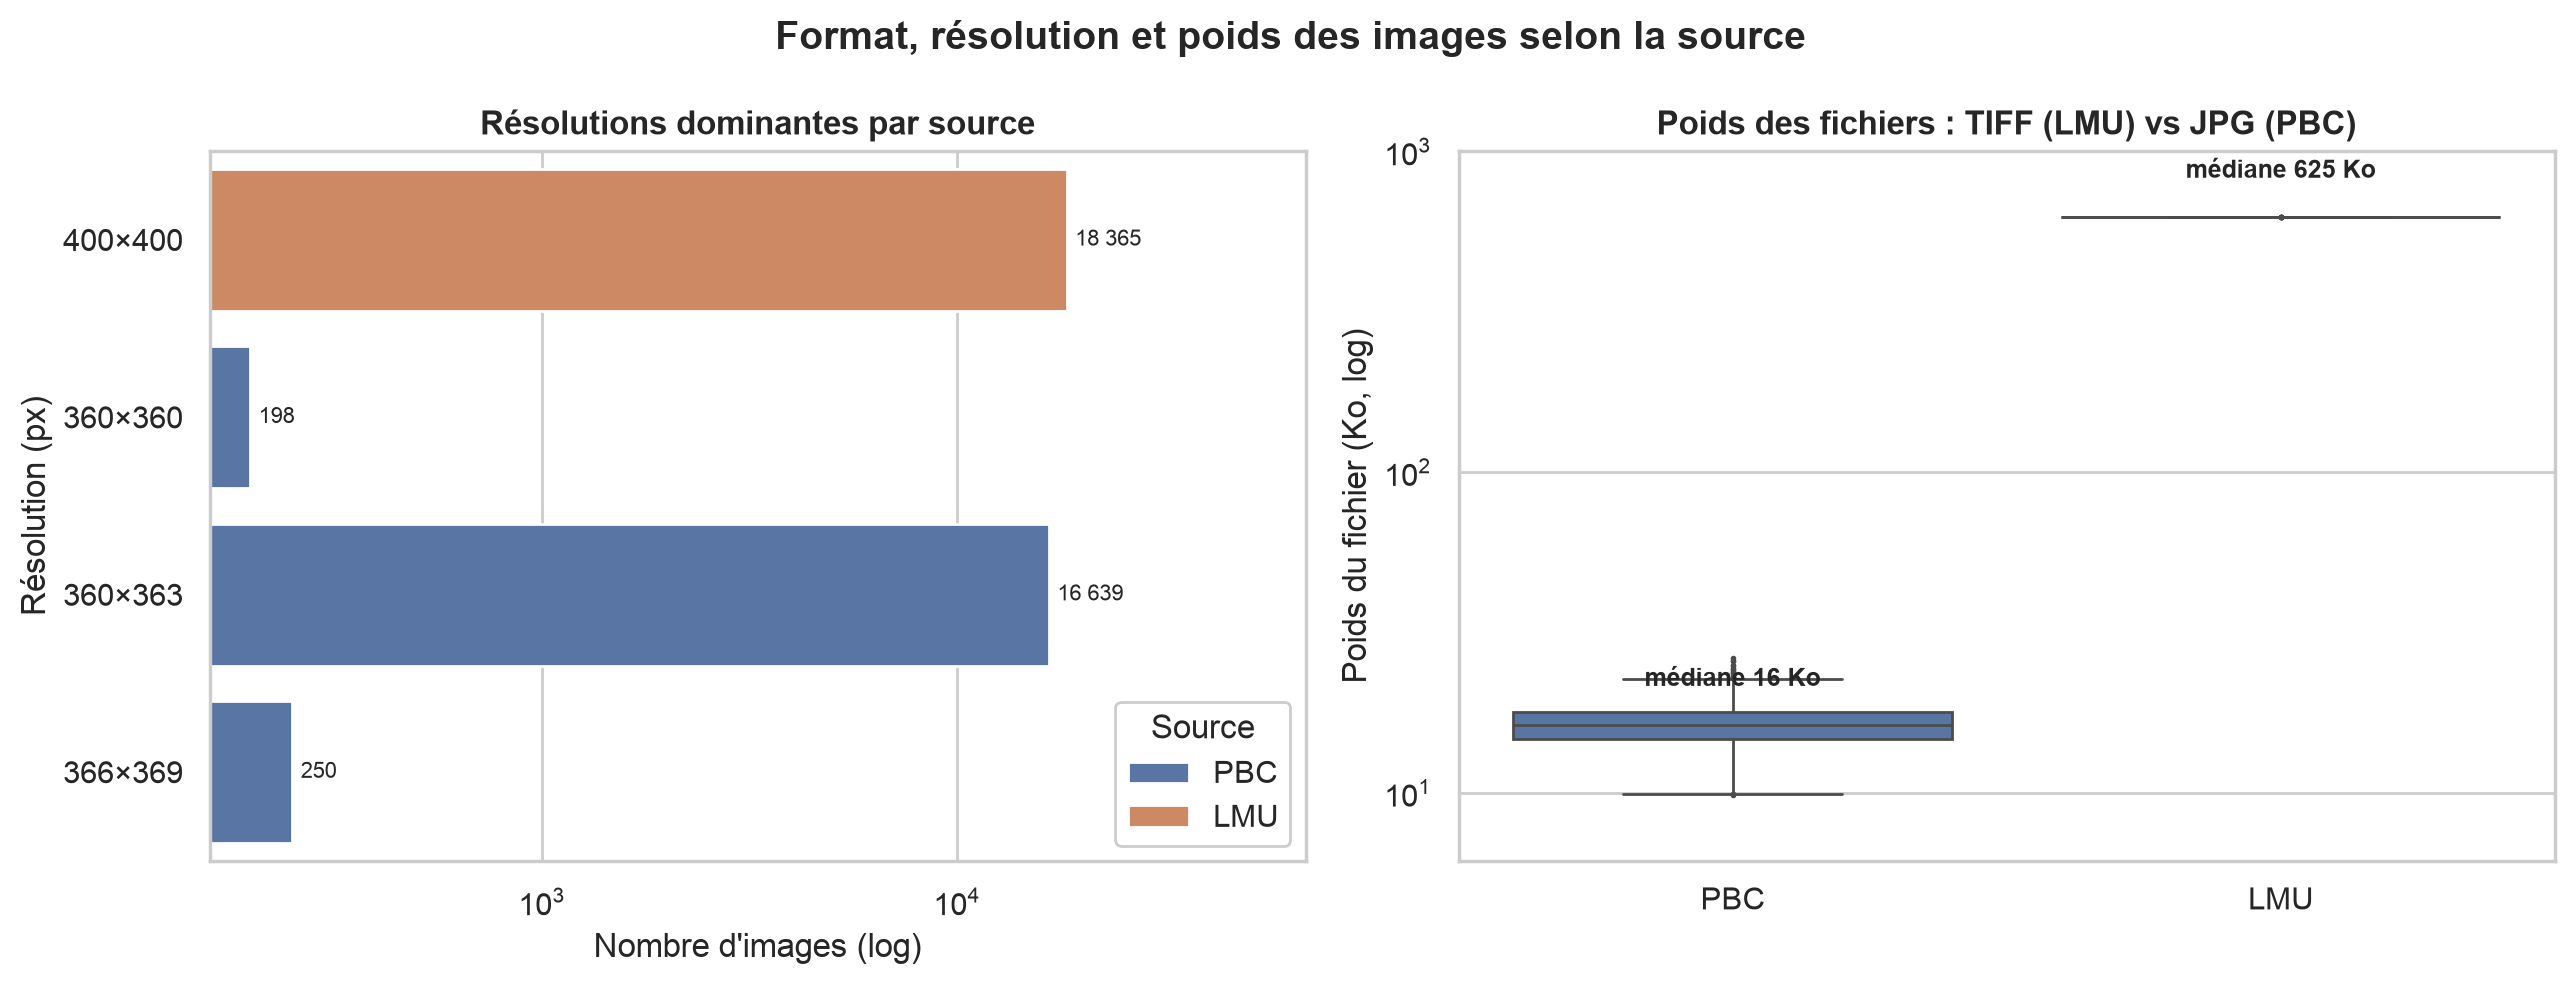

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

res = (df.assign(resolution=df["size_x"].astype(str) + "×" + df["size_y"].astype(str))
       .groupby(["source", "resolution"]).size().rename("n").reset_index())
res = res[res["n"] >= 20]
sns.barplot(data=res, y="resolution", x="n", hue="source", hue_order=SRC_ORDER,
            palette=SRC_COLORS, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_xlim(right=axes[0].get_xlim()[1] * 3)
axes[0].set_xlabel("Nombre d'images (log)")
axes[0].set_ylabel("Résolution (px)")
axes[0].set_title("Résolutions dominantes par source", fontweight="bold")
for c in axes[0].containers:
    labels = [f"{int(v):,}".replace(",", " ") if v else "" for v in c.datavalues]
    axes[0].bar_label(c, labels=labels, padding=3, fontsize=8)
axes[0].legend(title="Source", loc="lower right", framealpha=1)

sns.boxplot(data=sample, x="source", y="weight_kb", order=SRC_ORDER, hue="source",
            palette=SRC_COLORS, legend=False, ax=axes[1], fliersize=1)
axes[1].set_yscale("log")
axes[1].set_ylim(sample["weight_kb"].min() / 1.6, sample["weight_kb"].max() * 1.6)
axes[1].set_ylabel("Poids du fichier (Ko, log)")
axes[1].set_xlabel("")
med = sample.groupby("source")["weight_kb"].median()
for i, src in enumerate(SRC_ORDER):
    axes[1].annotate(f"médiane {med[src]:.0f} Ko", (i, med[src]), xytext=(0, 14),
                     textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
axes[1].set_title("Poids des fichiers : TIFF (LMU) vs JPG (PBC)", fontweight="bold")

fig.suptitle("Format, résolution et poids des images selon la source", fontsize=14,
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "format_images.png")
plt.show()

## Figure 7 — Projection PCA d'un échantillon (`fig:pca-source`)

  → reports/figures/report/pca_source.png


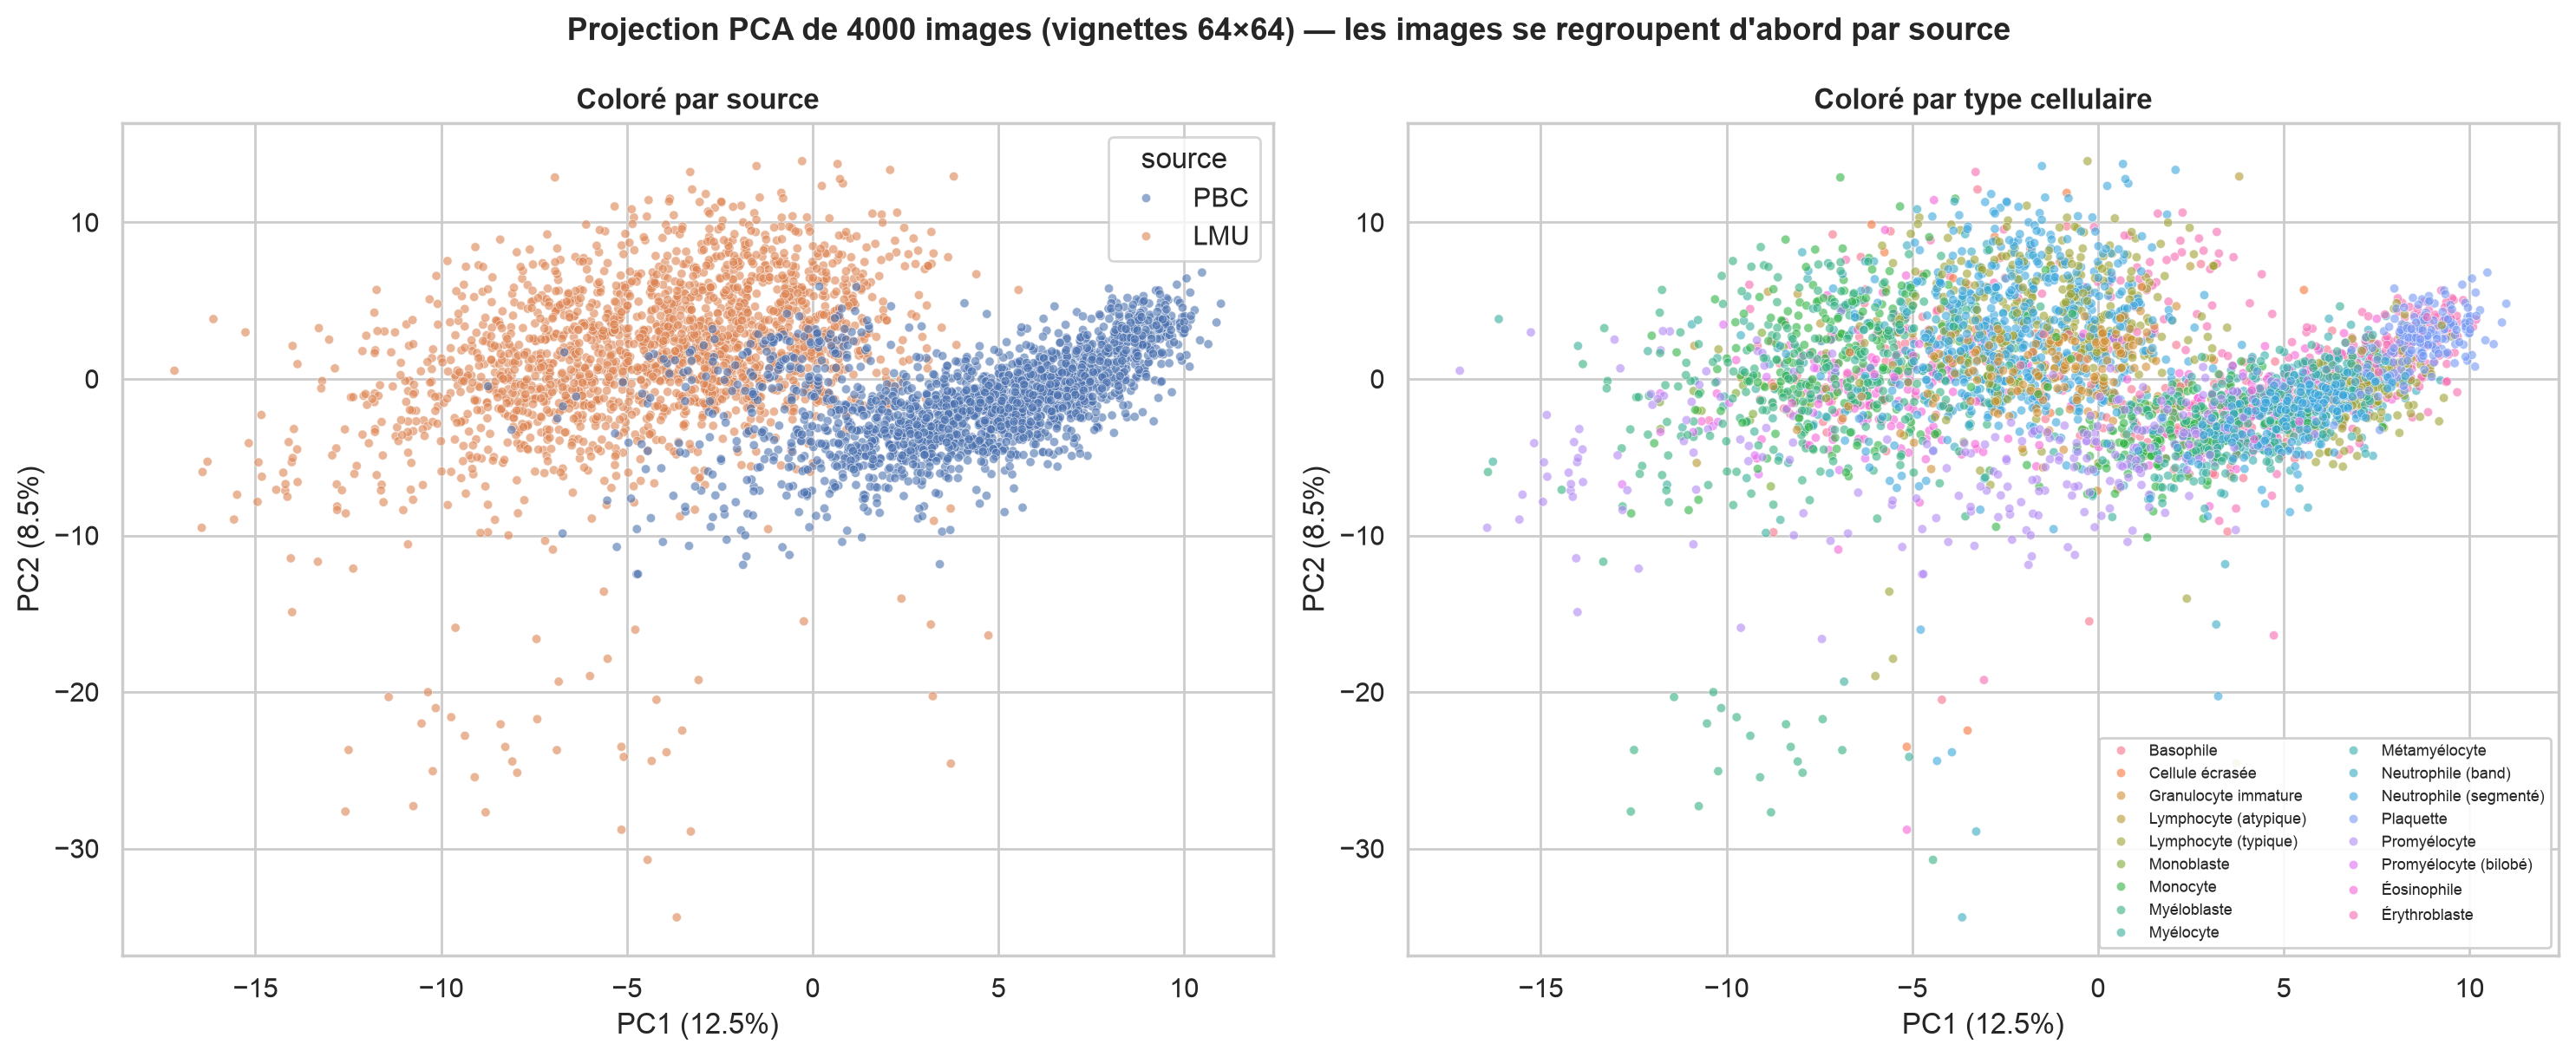

In [13]:
X = thumbs.reshape(len(thumbs), -1).astype(np.float32) / 255.0
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)
evr = pca.explained_variance_ratio_
pcs = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1],
                    "source": sample["source"].values, "cell": sample["cell"].values})

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="source", hue_order=SRC_ORDER,
                palette=SRC_COLORS, s=14, alpha=0.6, ax=axes[0])
axes[0].set_title("Coloré par source", fontweight="bold")

cell_hue_order = sorted(pcs["cell"].dropna().unique())
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="cell", hue_order=cell_hue_order, s=14,
                alpha=0.6, palette=sns.color_palette("husl", len(cell_hue_order)), ax=axes[1])
axes[1].set_title("Coloré par type cellulaire", fontweight="bold")
axes[1].legend(fontsize=6.5, ncol=2, loc="lower right", framealpha=0.9)

for ax in axes:
    ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
    ax.set_ylabel(f"PC2 ({evr[1]:.1%})")

fig.suptitle(f"Projection PCA de {len(sample)} images (vignettes {THUMB}×{THUMB}) — "
             "les images se regroupent d'abord par source", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "pca_source.png")
plt.show()

In [14]:
print("Fichiers générés dans", FIG_DIR.relative_to(ROOT), ":")
for p in sorted(FIG_DIR.glob("*.png")):
    print(f"  {p.name:32s} {p.stat().st_size / 1024:6.0f} Ko")

Fichiers générés dans reports/figures/report :
  format_images.png                    93 Ko
  histogrammes_rgb.png                164 Ko
  histogrammes_rgb_par_type.png       367 Ko
  luminosite_contraste.png            282 Ko
  mosaique_classes.png               1348 Ko
  mosaique_classes_lmu.png           1762 Ko
  mosaique_classes_pbc.png           1176 Ko
  nettete.png                         237 Ko
  pca_source.png                      986 Ko
  repartition_classes.png             130 Ko
